# Homework 10: Fairness EDA of the Communities and Crime Dataset
### DSA4970/5970
### Jake Van Slyke

In this assignment, you will perform a fairness exploratory data analysis on the Communities and Crime dataset, located in the UCI Machine Learning Repository.  You can find the location and documentation of the dataset here:  https://archive.ics.uci.edu/dataset/183/communities+and+crime.  

Using the notebook from class as a guide, conduct a full EDA on the dataset.  Then answer the questions in the markdown sections at the bottom of this notebook skeleton.  Run your entire notebook and save it.  Then upload it to the assignment page for lesson 10.

__This assignment is worth 200 points in total.__

In [1]:
# Check for the UCI Machine Learning Repository package and install if not present
import importlib
import subprocess
import sys
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression

def ensure_ucimlrepo():
    try:
        importlib.import_module("ucimlrepo")
        print("ucimlrepo is already installed.")
    except ImportError:
        print("ucimlrepo not found. Installing...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "ucimlrepo"])
        print("ucimlrepo installed successfully.")

ensure_ucimlrepo()


ucimlrepo is already installed.


In [2]:
# ---------------------------------------------------------
# Load Communities & Crime dataset from UCI ML Repository
# ---------------------------------------------------------

import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

# Load dataset
communities = fetch_ucirepo(id=183)

# Extract the main dataframe
df = communities.data.original

# ---------------------------------------------------------
# Select subset of variables
# ---------------------------------------------------------

fairness_vars = [
    # Location
    "state",
    "county",

    # Demographics / protected-attribute-adjacent
    "racepctblack",
    "racePctWhite",
    "racePctAsian",
    "racePctHisp",

    # Socioeconomic structure
    "medIncome",
    "MedRent",
    "PctUnemployed",
    "PctNotHSGrad",

    # Housing / neighborhood structure
    "PctForeignBorn",

    # Policing intensity
    "PolicPerPop",

    # Crime outcomes
    "ViolentCrimesPerPop",

]

# Keep only the fairness variables
df_fairness = df[fairness_vars].copy()

# Set up lists of dimensions
geoglist = ['state', 'county']
senslist = ['racepctblack', 'racePctWhite', 'racePctAsian', 'racePctHisp']

# Set up a list of measurements
dfcols = df_fairness.columns.tolist()
measures = [col for col in dfcols if (col not in senslist and col not in geoglist)]

# Replace "?" with actual NaN values
df_fairness['county'] = df_fairness['county'].apply(pd.to_numeric, errors='coerce').astype('Int64')
df_fairness[measures] = df_fairness[measures].apply(pd.to_numeric, errors='coerce')

# Preview
print(df_fairness.head())
print(df_fairness.shape)


   state  county  racepctblack  racePctWhite  racePctAsian  racePctHisp  \
0      8    <NA>          0.02          0.90          0.12         0.17   
1     53    <NA>          0.12          0.74          0.45         0.07   
2     24    <NA>          0.49          0.56          0.17         0.04   
3     34       5          1.00          0.08          0.12         0.10   
4     42      95          0.02          0.95          0.09         0.05   

   medIncome  MedRent  PctUnemployed  PctNotHSGrad  PctForeignBorn  \
0       0.37     0.34           0.27          0.18            0.12   
1       0.31     0.37           0.27          0.24            0.21   
2       0.30     0.31           0.36          0.43            0.14   
3       0.58     0.89           0.33          0.25            0.19   
4       0.50     0.38           0.12          0.30            0.11   

   PolicPerPop  ViolentCrimesPerPop  
0         0.13                 0.20  
1          NaN                 0.67  
2          NaN

#### Code (60 points)
Build your fairness EDA by adding code blocks to the notebook below this markdown section. Run all the relevant analyses.  Use the instructional_eda.ipynb notebook as a guide. Run your entire script to produce the outputs.

### 1. Sensitive attributes and grouping (Q1)

The largest normalized race value is a grouping proxy, not a verified population majority.

In [3]:
"""
Determine descriptive statistics for the sensitive attributes

Start by checking the descriptive statistics for the sensitive attributes.  You will see the variation
in the racial composition of the communities in the dataset.  Next, create a new column called 'majority_group'
that identifies the majority racial group in each community.  Use this categorical variable instead of the racial
percentages in your further analyses unless otherwise stated.

Some hints:
+ The measurement variables are all continuous.  So what test should you use when comparing distributions across groups?
+ You need to conduct significance tests for each pair of groups values.
+ You will need to use the Bonferroni correction to adjust for multiple distribution comparisons.  How many comparisons are you making?

""" 

# Begin your code here

from itertools import combinations
from IPython.display import display


def assign_majority_group(race_data, labels):
    """Label unique maxima; leave ties and incomplete rows unassigned."""
    unique_max = race_data.eq(race_data.max(axis=1), axis=0).sum(axis=1).eq(1)
    valid = race_data.notna().all(axis=1) & unique_max
    return race_data.loc[valid].idxmax(axis=1).map(labels)


alpha = 0.05
eda = df_fairness.copy()
race_names = dict(zip(senslist, ["Black", "White", "Asian", "Hispanic"]))
eda["majority_group"] = assign_majority_group(eda[senslist], race_names)
grouped = eda.dropna(subset=["majority_group"])

display(eda[senslist].describe().round(3))
print("Rows excluded from grouped analyses (ties or missing race data):",
      eda["majority_group"].isna().sum())
display(eda["majority_group"].value_counts().rename("communities"))


,racepctblack,racePctWhite,racePctAsian,racePctHisp
count,1994.000,1994.000,1994.000,1994.000
mean,0.180,0.754,0.154,0.144
std,0.253,0.244,0.209,0.232
min,0.000,0.000,0.000,0.000
25%,0.020,0.630,0.040,0.010
50%,0.060,0.850,0.070,0.040
75%,0.230,0.940,0.170,0.160
max,1.000,1.000,1.000,1.000


Rows excluded from grouped analyses (ties or missing race data): 8


majority_group
White       1566
Black        218
Hispanic     115
Asian         87
Name: communities, dtype: int64

### 2. Group summaries and distributions (Q2)

medIncome


,count,mean,median,std
majority_group,,,,
Asian,87,0.519,0.49,0.212
Black,218,0.199,0.17,0.118
Hispanic,115,0.224,0.21,0.112
White,1566,0.386,0.34,0.208


MedRent


,count,mean,median,std
majority_group,,,,
Asian,87,0.659,0.650,0.181
Black,218,0.253,0.215,0.135
Hispanic,115,0.318,0.290,0.177
White,1566,0.392,0.350,0.211


PctUnemployed


,count,mean,median,std
majority_group,,,,
Asian,87,0.304,0.26,0.151
Black,218,0.553,0.54,0.199
Hispanic,115,0.696,0.67,0.205
White,1566,0.315,0.29,0.162


... (4 outputs left out)

PolicPerPop


,count,mean,median,std
majority_group,,,,
Asian,25,0.123,0.10,0.072
Black,83,0.267,0.25,0.177
Hispanic,26,0.209,0.15,0.155
White,184,0.208,0.18,0.154


ViolentCrimesPerPop


,count,mean,median,std
majority_group,,,,
Asian,87,0.317,0.24,0.245
Black,218,0.565,0.54,0.279
Hispanic,115,0.415,0.36,0.231
White,1566,0.174,0.12,0.170


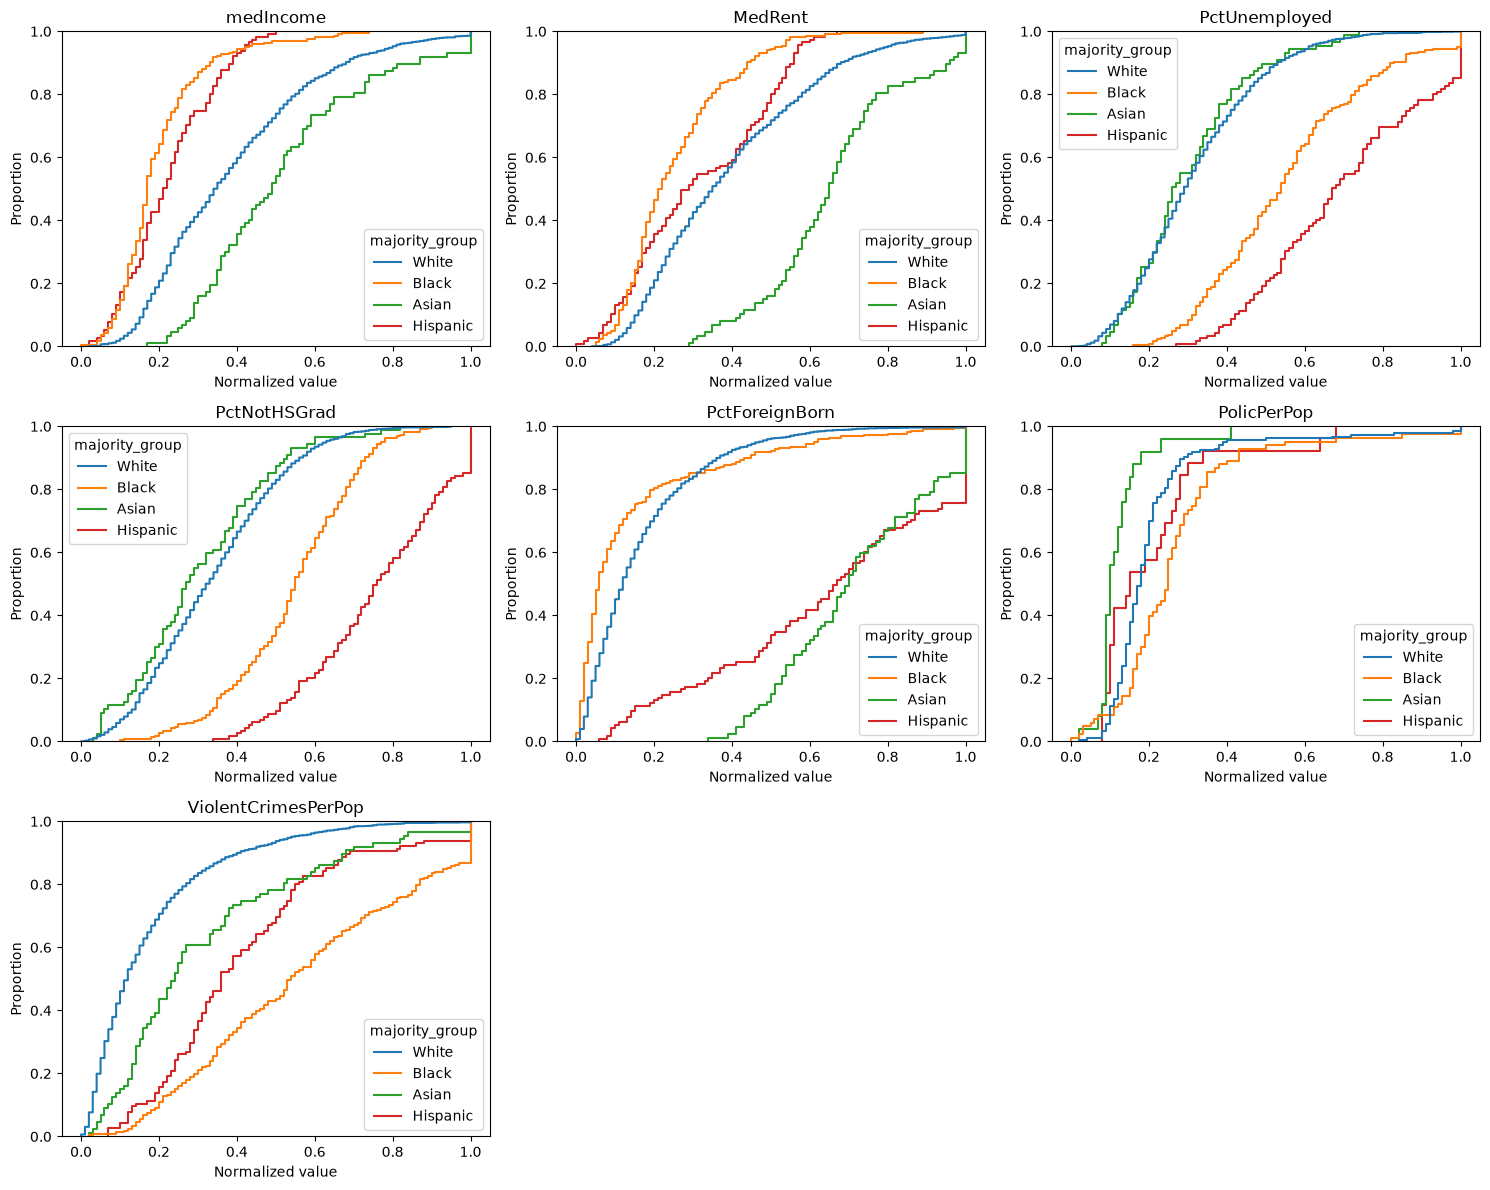

In [4]:
for measure in measures:
    print(measure)
    summary = grouped.groupby("majority_group")[measure].agg(
        ["count", "mean", "median", "std"]
    )
    display(summary.round(3))

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, measure in zip(axes.flat, measures):
    sns.ecdfplot(data=grouped, x=measure, hue="majority_group", ax=ax)
    ax.set(title=measure, xlabel="Normalized value")
for ax in list(axes.flat)[len(measures):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


### 3. Pairwise distribution tests (Q2)

Use Bonferroni correction across all comparisons. Rounded values create ties, so K-S p-values are approximate.

In [5]:
def pairwise_ks_tests(data, measurements, group_column, alpha=0.05):
    """Compare every group pair, correcting across all measurements."""
    pairs = list(combinations(sorted(data[group_column].dropna().unique()), 2))
    n_comparisons = len(measurements) * len(pairs)
    rows = []

    for measure in measurements:
        for group_a, group_b in pairs:
            x = data.loc[data[group_column] == group_a, measure].dropna()
            y = data.loc[data[group_column] == group_b, measure].dropna()
            if min(len(x), len(y)) < 2:
                print(f"Skipping {measure}: {group_a} vs {group_b} (too few observations)")
                continue
            result = stats.ks_2samp(x, y)
            rows.append([
                measure, group_a, group_b, len(x), len(y),
                result.statistic, result.pvalue,
            ])

    results = pd.DataFrame(rows, columns=[
        "measurement", "group_a", "group_b", "n_a", "n_b", "KS_D", "p_value",
    ])
    results["p_bonferroni"] = (results["p_value"] * n_comparisons).clip(upper=1)
    results["significant"] = results["p_bonferroni"] < alpha
    return results, len(pairs), n_comparisons


ks_results, n_pairs, n_comparisons = pairwise_ks_tests(
    grouped, measures, "majority_group", alpha
)
print(f"{len(measures)} measurements x {n_pairs} pairs = {n_comparisons} comparisons")
print(f"Bonferroni significance cutoff: {alpha / n_comparisons:.6g}")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(ks_results)
print("Measurements with at least one significant pair:")
print(ks_results.loc[ks_results["significant"], "measurement"].unique())


7 measurements x 6 pairs = 42 comparisons
Bonferroni significance cutoff: 0.00119048


,measurement,group_a,group_b,n_a,n_b,KS_D,p_value,p_bonferroni,significant
0,medIncome,Asian,Black,87,218,0.749815,5.036616e-35,2.115379e-33,True
1,medIncome,Asian,Hispanic,87,115,0.638481,1.569268e-19,6.590925e-18,True
2,medIncome,Asian,White,87,1566,0.305236,2.701289e-07,1.134542e-05,True
3,medIncome,Black,Hispanic,218,115,0.189749,7.407972e-03,3.111348e-01,False
4,medIncome,Black,White,218,1566,0.462840,7.846504e-38,3.295532e-36,True
5,medIncome,Hispanic,White,115,1566,0.346971,5.176457e-12,2.174112e-10,True
6,MedRent,Asian,Black,87,218,0.793314,7.078308e-40,2.972890e-38,True
7,MedRent,Asian,Hispanic,87,115,0.646177,4.248371e-20,1.784316e-18,True
8,MedRent,Asian,White,87,1566,0.556833,1.893694e-24,7.953513e-23,True
9,MedRent,Black,Hispanic,218,115,0.265536,3.535854e-05,1.485058e-03,True


Measurements with at least one significant pair:
['medIncome' 'MedRent' 'PctUnemployed' 'PctNotHSGrad' 'PctForeignBorn'
 'PolicPerPop' 'ViolentCrimesPerPop']


### 4. Missingness (Q3–Q4)

Model missingness using observed predictors. This is not Little's MCAR test; observed associations cannot distinguish MAR from MNAR.

In [6]:
missing_summary = pd.DataFrame({
    "missing_count": eda[measures].isna().sum(),
    "missing_percent": 100 * eda[measures].isna().mean(),
}).sort_values("missing_count", ascending=False)
display(missing_summary.round(2))

highest_missing = missing_summary.index[0]
remaining_measures = [m for m in measures if m != highest_missing]
print("Highest-missingness measurement:", highest_missing)

eda["is_missing"] = eda[highest_missing].isna().astype(int)
print("Percent missing by group:")
display((100 * eda.groupby("majority_group")["is_missing"].mean()).round(2))

missing_predictors = ["majority_group"] + remaining_measures
missing_data = eda[["is_missing"] + missing_predictors].dropna()
X_missing = pd.get_dummies(
    missing_data[missing_predictors], drop_first=True
).astype(float)
X_missing = sm.add_constant(X_missing)
y_missing = missing_data["is_missing"]
missing_model = sm.Logit(y_missing, X_missing).fit(
    method="bfgs", maxiter=1000, disp=False
)

print(f"Missingness regression uses {len(missing_data)} of {len(eda)} rows.")
print(missing_model.summary())
print("Converged:", missing_model.mle_retvals["converged"])


,missing_count,missing_percent
PolicPerPop,1675,84.0
medIncome,0,0.0
MedRent,0,0.0
PctUnemployed,0,0.0
PctNotHSGrad,0,0.0
PctForeignBorn,0,0.0
ViolentCrimesPerPop,0,0.0


Highest-missingness measurement: PolicPerPop
Percent missing by group:


majority_group
Asian       71.26
Black       61.93
Hispanic    77.39
White       88.25
Name: is_missing, dtype: float64

Missingness regression uses 1986 of 1994 rows.
                           Logit Regression Results                           
Dep. Variable:             is_missing   No. Observations:                 1986
Model:                          Logit   Df Residuals:                     1976
Method:                           MLE   Df Model:                            9
Date:                Wed, 25 Nov 2026   Pseudo R-squ.:                  0.1887
Time:                        13:17:26   Log-Likelihood:                -708.77
converged:                       True   LL-Null:                       -873.58
Covariance Type:            nonrobust   LLR p-value:                 1.341e-65
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                       2.5066      0.514      4.876      0.000       1.499       3.514
medIncome                   1.0657      0.864

### 5. Correlations (Q5–Q6)

Use numeric race variables and the remaining measurements; state and county are identifiers.

Dropped PolicPerPop; using 1994 of 1994 rows.


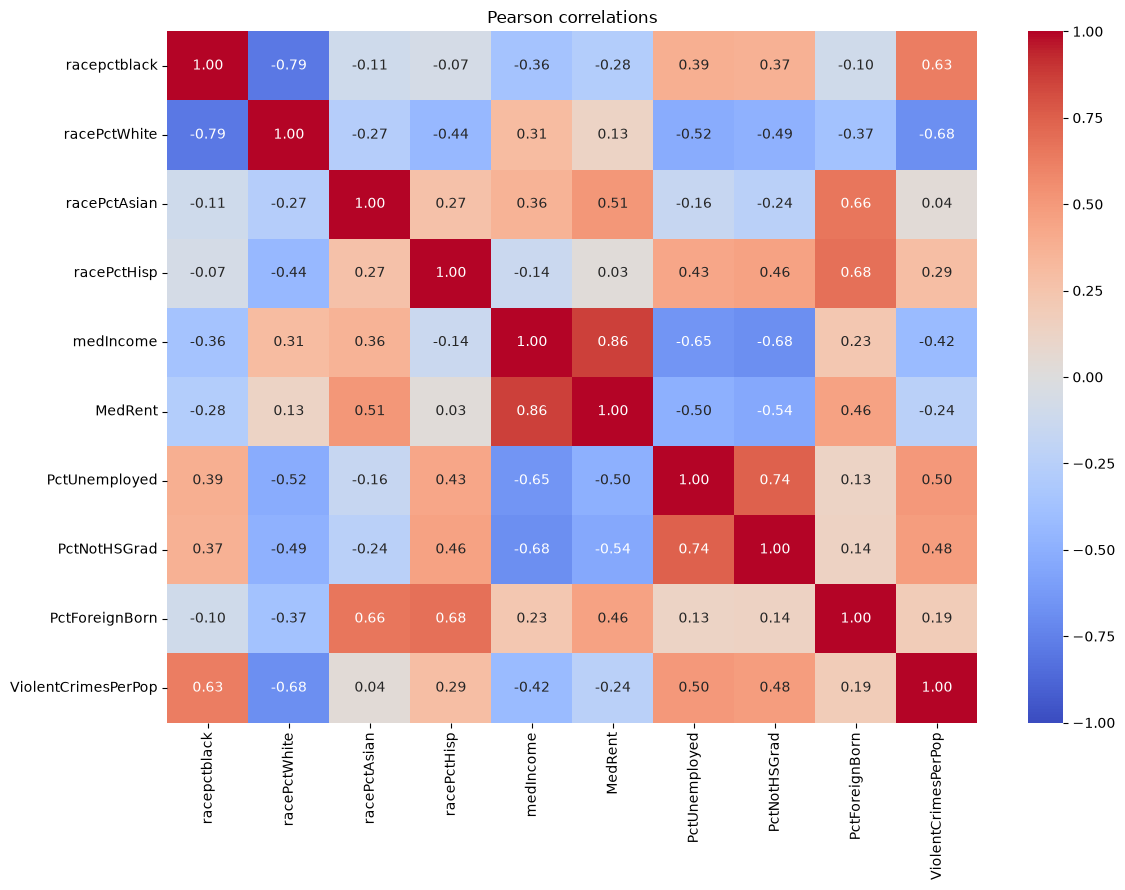

Measurement-sensitive correlations (strongest first):


,measurement,sensitive_attribute,pearson_r
21,ViolentCrimesPerPop,racePctWhite,-0.6848
19,PctForeignBorn,racePctHisp,0.6842
18,PctForeignBorn,racePctAsian,0.6575
20,ViolentCrimesPerPop,racepctblack,0.6313
9,PctUnemployed,racePctWhite,-0.5175
6,MedRent,racePctAsian,0.5100
13,PctNotHSGrad,racePctWhite,-0.4856
15,PctNotHSGrad,racePctHisp,0.4556
11,PctUnemployed,racePctHisp,0.4326
8,PctUnemployed,racepctblack,0.3883


In [7]:
corr_data = eda[senslist + remaining_measures].dropna()
corr_matrix = corr_data.corr(method="pearson")
print(f"Dropped {highest_missing}; using {len(corr_data)} of {len(eda)} rows.")

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, center=0,
)
plt.title("Pearson correlations")
plt.tight_layout()
plt.show()

race_correlations = (
    corr_matrix.loc[remaining_measures, senslist]
    .rename_axis(index="measurement", columns="sensitive_attribute")
    .stack()
    .rename("pearson_r")
    .reset_index()
    .sort_values("pearson_r", key=abs, ascending=False)
)
print("Measurement-sensitive correlations (strongest first):")
display(race_correlations.round(4))


### 6. Conditional outcome differences (Q7)

In [8]:
target = "ViolentCrimesPerPop"
predictors = senslist + [m for m in remaining_measures if m != target]
reg_data = eda[predictors + [target]].dropna()

X = sm.add_constant(reg_data[predictors].astype(float))
y = reg_data[target].astype(float)
model = sm.OLS(y, X).fit()

print(f"Outcome regression uses {len(reg_data)} of {len(eda)} rows.")
print(model.summary())


Outcome regression uses 1994 of 1994 rows.
                             OLS Regression Results                            
Dep. Variable:     ViolentCrimesPerPop   R-squared:                       0.559
Model:                             OLS   Adj. R-squared:                  0.557
Method:                  Least Squares   F-statistic:                     279.6
Date:                 Wed, 25 Nov 2026   Prob (F-statistic):               0.00
Time:                         13:17:27   Log-Likelihood:                 892.56
No. Observations:                 1994   AIC:                            -1765.
Df Residuals:                     1984   BIC:                            -1709.
Df Model:                            9                                         
Covariance Type:             nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

#### Q1 (20 points): What is the sensitive attribute in this dataset?

The sensitive attribute is the racial/ethnic makeup of each community. It's represented by `racepctblack`, `racePctWhite`, `racePctAsian`, and `racePctHisp`. I used the largest of these values to assign `majority_group`. Since the columns are normalized separately, this is just a way to group the communities and doesn't necessarily identify the actual majority. I left out eight rows where the largest values were tied.


#### Q2 (20 points): From your stratified distribution analysis, which variables have a statistically significant difference by sensitive attribute?

All seven measurements had a significant difference for at least one pair of groups: `medIncome`, `MedRent`, `PctUnemployed`, `PctNotHSGrad`, `PctForeignBorn`, `PolicPerPop`, and `ViolentCrimesPerPop`. I used K-S tests with a Bonferroni correction for 42 comparisons, giving a cutoff of $0.05/42 \approx 0.00119$. Not every pair was significant. For example, the Asian and White proxy groups didn't differ significantly in unemployment, but violent crime differed across all six pairs.


#### Q3 (20 points): Which measurement variable has the highest level of missingness?

`PolicPerPop` had the most missing data, with 1,675 out of 1,994 rows missing, or about 84%. The other six measurements had no missing values.


#### Q4 (20 points): Is this variable MCAR, MAR, or MNAR?  Explain your answer.

The results suggest `PolicPerPop` is not MCAR because its missingness is related to variables we can observe. In the missingness regression, `PctNotHSGrad`, `PctForeignBorn`, and `ViolentCrimesPerPop` were all significant ($p < .001$). Missingness also ranged from about 62% in the Black proxy group to 88% in the White proxy group. I'd treat MAR as a working assumption if the observed variables explain the missingness, but this analysis can't confirm MAR or rule out MNAR.


#### Q5 (20 points): To look for correlations or associations within one heatmap, all variables must be numerical (correlation) or all must be categorical (association).  Because we have numerical values for the percentages of racial groups in each neighborhood (e.g. racepctblack), we can use those instead of majority_group with our measures to create a set of only numerical variables.  What statistic do we use in this case to generate our heatmap?

I used Pearson's correlation coefficient, $r$, since the variables are numerical. It ranges from $-1$ to $1$. Negative values mean the variables tend to move in opposite directions, positive values mean they tend to move together, and values near zero mean little linear relationship.


#### Q6 (20 points): Produce a heatmap with all numerical variables.  Drop the highest missingness measurement variable so you can keep most of your rows.  What measures are related to your sensitive attribute(s)?  Which one has the greatest degree of correlation or association to a sensitive attribute?  What is the value of its correlation or association and to what sensitive attribute is it related?

I dropped `PolicPerPop` for the heatmap, which let me keep all 1,994 rows. All six remaining measurements had a relationship with at least one sensitive attribute. The strongest correlation for each measurement was:

| Measurement | Sensitive attribute | Pearson $r$ |
| --- | --- | ---: |
| `medIncome` | `racePctAsian` | 0.3630 |
| `MedRent` | `racePctAsian` | 0.5100 |
| `PctUnemployed` | `racePctWhite` | -0.5175 |
| `PctNotHSGrad` | `racePctWhite` | -0.4856 |
| `PctForeignBorn` | `racePctHisp` | 0.6842 |
| `ViolentCrimesPerPop` | `racePctWhite` | -0.6848 |

The strongest overall was `ViolentCrimesPerPop` with `racePctWhite`, at $r = -0.6848$. Communities with higher values of `racePctWhite` tended to have lower violent crime values. This doesn't mean one causes the other.


#### Q7 (20 points): Consider violent crimes per population as the target variable. Is there a conditional outcome difference based upon the sensitive attribute(s)? Explain how you know if there is or is not.  To answer this question, perform a regression using only numeric variables.  Don't use majority_group -- you can simplify the regression by avoiding one-hot encoding by sticking with numeric variables.  Also, exclude the measure with the highest missingness -- OLS regression cannot handle missing values.

Yes, the OLS results show a conditional outcome difference after accounting for the other predictors. `racepctblack` had a coefficient of 0.4665 and `racePctHisp` had a coefficient of 0.1456, both with $p < .001$. `racePctWhite` ($p = .377$) and `racePctAsian` ($p = .444$) weren't significant at the .05 level. I left out `PolicPerPop`, so the model used all 1,994 rows and had $R^2 = .559$. These are relationships between community-level variables on the normalized scale, so they don't show causation or tell us about individual people.
